# 07 — Gộp dữ liệu 8 thành phố

Notebook này làm 4 việc, theo đúng thứ tự:

1. **Chuẩn hoá Lucknow và Jaipur**: hai thành phố này mới chỉ có file ở `data/interim/`, chưa có `*_clean.csv` trong `data/processed/`. Ở đây tạo file đó, và đổi cách đánh dấu outlier về cùng quy tắc với 6 thành phố còn lại (IQR theo tháng, chỉ đánh dấu, không sửa giá trị).
2. **Áp quyết định chung "bỏ cột Xylene"** cho Amritsar (file cũ còn giữ Xylene).
3. **Gộp 8 thành phố** thành một bảng `data/processed/air_quality_8cities.csv` và kiểm tra bằng `assert`.
4. **Sinh bảng tóm tắt làm sạch** `reports/cleaning_summary_8cities.csv` và biểu đồ missing còn lại.

Quy ước: notebook này **không sửa giá trị nồng độ** của bất kỳ thành phố nào, chỉ đổi tên/đánh dấu cột và bỏ cột Xylene.

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import (flag_outliers_iqr, flag_flatline_zeros, validity_checks,
                   check_consistency, check_duplicates, AQI_LABELS)

RAW       = "../data/raw/city_day.csv"
INTERIM   = "../data/interim"
PROCESSED = "../data/processed"
REPORTS   = "../reports"
os.makedirs(f"{REPORTS}/figures", exist_ok=True)

CITIES = ["Delhi", "Gurugram", "Lucknow", "Jaipur",
          "Bengaluru", "Amritsar", "Chennai", "Hyderabad"]

# 11 chất sau khi bỏ Xylene (quyết định chung của nhóm: Xylene thiếu 100% ở 4/8 thành phố)
POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
              "CO", "SO2", "O3", "Benzene", "Toluene"]
PM_RATIO = 1.2   # PM2.5 > 1,2 x PM10 thì coi là vô lý (PM10 đã gồm cả PM2.5) — cùng ngưỡng nhóm Jaipur đã dùng

## Bước 1 — Lucknow và Jaipur: tạo file `*_clean.csv`

Hai thành phố này trước đó dùng một bộ cờ outlier riêng (`*_iqr_flag`, `*_ctx_flag`, tính trên toàn bộ chuỗi),
khác 6 thành phố còn lại (`<cột>_is_outlier`, IQR **theo từng tháng**). Nếu để nguyên thì gộp lại sẽ lệch cột.

Cách xử lý:
- Giữ nguyên toàn bộ **giá trị** đã làm sạch (flatline → NaN, nội suy gap ≤ 14 ngày, các điểm nghi lỗi cảm biến đã đặt NaN).
- Bỏ các cột cờ riêng, chạy lại `flag_outliers_iqr()` của `utils.py` để có `<cột>_is_outlier` cùng quy tắc.
- Giữ cột `suspect_sensor_error` (đánh dấu ngày bị đặt NaN vì nghi lỗi cảm biến) vì đây là thông tin thật, chỉ có ở 2 thành phố này.

In [2]:
def finalize_lucknow_jaipur(city):
    df = pd.read_csv(f"{INTERIM}/{city.lower()}_after_outliers.csv", parse_dates=["Date"])

    own_flags = [c for c in df.columns
                 if c.endswith(("_iqr_flag", "_ctx_flag")) or c == "pm25_gt_pm10_flag"]
    df = df.drop(columns=own_flags + [c for c in df.columns if c.startswith("Xylene") and c != "Xylene_was_missing"])

    df = flag_outliers_iqr(df, cols=POLLUTANTS)     # chỉ đánh dấu, không đổi giá trị

    present  = [p for p in POLLUTANTS if p in df.columns]
    was_miss = [c for c in df.columns if c.endswith("_was_missing")]
    outl     = [f"{p}_is_outlier" for p in present]
    extra    = ["suspect_sensor_error"]
    order = ["Date", "City"] + present + ["AQI", "AQI_Bucket"] + was_miss + outl + extra
    return df[order].sort_values("Date").reset_index(drop=True)

for city in ["Lucknow", "Jaipur"]:
    out = finalize_lucknow_jaipur(city)
    out.to_csv(f"{PROCESSED}/{city.lower()}_clean.csv", index=False)
    n_flag = int(out[[c for c in out.columns if c.endswith('_is_outlier')]].sum().sum())
    print(f"{city}: {out.shape}  | cột PM10 có mặt: {'PM10' in out.columns} | tổng ô bị đánh dấu outlier: {n_flag}")

Lucknow: (2009, 38)  | cột PM10 có mặt: False | tổng ô bị đánh dấu outlier: 950
Jaipur: (1114, 40)  | cột PM10 có mặt: True | tổng ô bị đánh dấu outlier: 467


## Bước 2 — Amritsar: bỏ Xylene cho đúng quyết định chung

Amritsar là thành phố duy nhất còn giữ cột `Xylene` (các thành phố khác đã bỏ). Bỏ cột này (và các cột `Xylene_*` đi kèm)
để 8 thành phố cùng một bộ cột. Chạy lại notebook không gây lỗi vì chỉ bỏ cột nếu nó còn tồn tại.

In [3]:
am = pd.read_csv(f"{PROCESSED}/amritsar_clean.csv", parse_dates=["Date"])
xyl = [c for c in am.columns if c.startswith("Xylene")]
print("Cột Xylene* còn trong Amritsar:", xyl)
if xyl:
    am = am.drop(columns=xyl)
    am.to_csv(f"{PROCESSED}/amritsar_clean.csv", index=False)
    print("-> đã bỏ và lưu lại amritsar_clean.csv:", am.shape)

Cột Xylene* còn trong Amritsar: []


## Bước 3 — Gộp 8 thành phố

Quy tắc gộp:
- Giữ **tất cả** ngày mà mỗi thành phố có dữ liệu (không cắt về khoảng chung) — khi phân tích có thể lọc sau.
- `PM10` của Lucknow không có (bỏ vì thiếu 100%) → sau khi gộp là NaN, và `PM10_was_missing = True`.
- `*_is_outlier`: ô không có giá trị → `False` (cùng quy ước với `flag_outliers_iqr`).
- Thêm 2 cột cờ dùng chung cho cả 8 thành phố, **chỉ đánh dấu**, không sửa giá trị:
  - `pm25_gt_pm10_flag`: PM2.5 > 1,2 × PM10. Để trống (`<NA>`) khi thiếu một trong hai giá trị (Lucknow không có PM10 nên luôn trống).
  - `suspect_sensor_error`: chỉ Lucknow/Jaipur đã làm bước này. 6 thành phố còn lại để trống (`<NA>`) = **chưa kiểm tra**, không có nghĩa là "đã kiểm tra và sạch".

In [4]:
frames = []
for city in CITIES:
    df = pd.read_csv(f"{PROCESSED}/{city.lower()}_clean.csv", parse_dates=["Date"])
    df = df.drop(columns=[c for c in df.columns if c.startswith("Xylene")])
    frames.append(df)

merged = pd.concat(frames, ignore_index=True, sort=False)

# --- cờ outlier: ô không có giá trị -> False
for p in POLLUTANTS:
    col = f"{p}_is_outlier"
    merged[col] = merged[col].fillna(False).astype(bool)

# --- cờ was_missing: Lucknow không có cột PM10 nên ô PM10 phải coi là "thiếu"
for p in POLLUTANTS + ["AQI"]:
    col = f"{p}_was_missing"
    merged[col] = merged[col].fillna(True).astype(bool)

# --- cờ vô lý PM2.5 > PM10 (dùng chung quy tắc cho cả 8 thành phố)
both = merged["PM2.5"].notna() & merged["PM10"].notna()
flag = (merged["PM2.5"] > PM_RATIO * merged["PM10"]).astype("boolean")
flag[~both] = pd.NA
merged["pm25_gt_pm10_flag"] = flag

# --- suspect_sensor_error: chỉ 2 thành phố đã kiểm tra; còn lại = chưa kiểm tra (NA)
merged["suspect_sensor_error"] = merged["suspect_sensor_error"].astype("boolean")

order = (["Date", "City"] + POLLUTANTS + ["AQI", "AQI_Bucket"]
         + [f"{p}_was_missing" for p in POLLUTANTS + ["AQI"]]
         + [f"{p}_is_outlier" for p in POLLUTANTS]
         + ["pm25_gt_pm10_flag", "suspect_sensor_error"])
merged = merged[order]
merged["City"] = pd.Categorical(merged["City"], categories=CITIES, ordered=True)
merged = merged.sort_values(["City", "Date"]).reset_index(drop=True)
merged["City"] = merged["City"].astype(str)

merged.to_csv(f"{PROCESSED}/air_quality_8cities.csv", index=False)
print(merged.shape)
merged.groupby("City", sort=False).agg(rows=("Date", "size"), tu=("Date", "min"), den=("Date", "max"))

(14056, 40)


,rows,tu,den
City,,,
Delhi,2009,2015-01-01,2020-07-01
Gurugram,1679,2015-11-27,2020-07-01
Lucknow,2009,2015-01-01,2020-07-01
Jaipur,1114,2017-06-14,2020-07-01
Bengaluru,2009,2015-01-01,2020-07-01
Amritsar,1221,2017-02-27,2020-07-01
Chennai,2009,2015-01-01,2020-07-01
Hyderabad,2006,2015-01-04,2020-07-01


## Bước 4 — Kiểm tra sau khi gộp

Mỗi `assert` là một điều bắt buộc phải đúng. Nếu có dòng nào báo lỗi nghĩa là việc gộp đang sai và không được dùng file này.

In [5]:
raw = pd.read_csv(RAW, parse_dates=["Date"])
raw8 = raw[raw.City.isin(CITIES)]

# 1) không mất / không thừa ngày so với file gốc
rows_raw = raw8.groupby("City").size()
rows_new = merged.groupby("City").size()
assert (rows_raw.reindex(CITIES) == rows_new.reindex(CITIES)).all(), "Số dòng mỗi thành phố khác file gốc"

# 2) không trùng khoá (City, Date), đủ 8 thành phố
assert check_duplicates(merged) == 0, "Có dòng trùng City+Date"
assert merged.City.nunique() == 8

# 3) không còn cột Xylene
assert not [c for c in merged.columns if "Xylene" in c]

# 4) ngày chỉ nằm trong khoảng của file gốc, và liên tục (không thiếu ngày giữa chừng)
assert merged.Date.min() >= raw8.Date.min() and merged.Date.max() <= raw8.Date.max()
for city, g in merged.groupby("City"):
    assert (g.Date.max() - g.Date.min()).days + 1 == len(g), f"{city} bị thiếu ngày giữa chuỗi"

# 5) quy tắc hợp lệ của utils: không âm, AQI_Bucket khớp AQI
vc = validity_checks(merged, cols=POLLUTANTS)
assert vc.n_violations.sum() == 0, vc[vc.n_violations > 0]
assert not check_consistency(merged), check_consistency(merged)

# 6) giá trị trong bảng gộp giống hệt file từng thành phố (gộp không làm đổi số liệu)
for city in CITIES:
    one = pd.read_csv(f"{PROCESSED}/{city.lower()}_clean.csv", parse_dates=["Date"]).set_index("Date")
    mg  = merged[merged.City == city].set_index("Date")
    for p in [x for x in POLLUTANTS if x in one.columns] + ["AQI"]:
        a, b = one[p], mg.loc[one.index, p]
        assert ((a == b) | (a.isna() & b.isna())).all(), f"{city}/{p} bị lệch sau khi gộp"

# 7) nhãn AQI_Bucket đều thuộc 6 nhãn chuẩn
assert set(merged.AQI_Bucket.dropna().unique()) <= set(AQI_LABELS)

print("TẤT CẢ KIỂM TRA ĐỀU ĐẠT")
print("Tổng số dòng:", len(merged), "| số cột:", merged.shape[1])

TẤT CẢ KIỂM TRA ĐỀU ĐẠT
Tổng số dòng: 14056 | số cột: 40


In [6]:
# Còn bao nhiêu % ô bị thiếu sau làm sạch (đã chủ ý giữ NaN ở khối trống dài, không bịa số)
miss = (merged.groupby("City")[POLLUTANTS + ["AQI"]].apply(lambda g: g.isna().mean() * 100)
        .reindex(CITIES).round(0))
miss

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
City,,,,,,,,,,,,
Delhi,0.0,2.0,0.0,0.0,0.0,0.0,3.0,4.0,3.0,0.0,4.0,0.0
Gurugram,4.0,52.0,2.0,2.0,21.0,93.0,2.0,1.0,1.0,36.0,46.0,13.0
Lucknow,4.0,100.0,0.0,0.0,14.0,50.0,0.0,0.0,0.0,6.0,7.0,6.0
Jaipur,1.0,0.0,0.0,0.0,10.0,0.0,5.0,0.0,0.0,5.0,0.0,2.0
Bengaluru,4.0,16.0,0.0,0.0,16.0,5.0,0.0,0.0,1.0,4.0,0.0,5.0
Amritsar,5.0,0.0,3.0,0.0,21.0,0.0,14.0,4.0,3.0,8.0,10.0,8.0
Chennai,4.0,83.0,0.0,0.0,0.0,20.0,0.0,0.0,0.0,5.0,3.0,6.0
Hyderabad,5.0,15.0,0.0,0.0,0.0,15.0,2.0,0.0,0.0,5.0,5.0,6.0


### Cờ vô lý PM2.5 > PM10 ở từng thành phố

Trước đây chỉ Jaipur có kiểm tra này. Giờ cả 8 thành phố dùng chung một quy tắc (chỉ đánh dấu, không sửa).

In [7]:
chk = merged.groupby("City").agg(
    ngay_kiem_tra_duoc=("pm25_gt_pm10_flag", lambda s: int(s.notna().sum())),
    ngay_bi_co=("pm25_gt_pm10_flag", lambda s: int(s.fillna(False).sum())),
).reindex(CITIES)
chk["ty_le_%"] = (chk.ngay_bi_co / chk.ngay_kiem_tra_duoc * 100).round(1)
chk

,ngay_kiem_tra_duoc,ngay_bi_co,ty_le_%
City,,,
Delhi,1965,8,0.4
Gurugram,814,14,1.7
Lucknow,0,0,<NA>
Jaipur,1108,4,0.4
Bengaluru,1689,61,3.6
Amritsar,1165,10,0.9
Chennai,339,40,11.8
Hyderabad,1702,33,1.9


## Bước 5 — Bảng tóm tắt làm sạch cho cả 8 thành phố

`reports/cleaning_log.csv` cũ bị sai định dạng (dòng đầu là ghi chú, thiếu Delhi/Gurugram). Bảng dưới được **tính lại trực tiếp từ file gốc và file đã làm sạch**,
nên mọi con số kiểm chứng được. Mỗi dòng là 1 thành phố × 1 cột, với phép cân đối bắt buộc đúng:

`missing_cuối = missing_gốc + flatline→NaN − đã nội suy + NaN thêm sau`

In [8]:
RAW_COLS = POLLUTANTS + ["Xylene"]
rows = []
for city in CITIES:
    r = raw[raw.City == city].sort_values("Date").reset_index(drop=True)
    _, flat = flag_flatline_zeros(r, cols=RAW_COLS, min_run=3)
    m = merged[merged.City == city].reset_index(drop=True)
    n = len(r)

    for col in RAW_COLS + ["AQI"]:
        n_before = int(r[col].isna().sum())
        row = dict(city=city, column=col, n_days=n, n_missing_before=n_before,
                   pct_missing_before=round(n_before / n * 100, 1))
        if col == "Xylene" or (city == "Lucknow" and col == "PM10"):
            row.update(status="dropped", note="thiếu 100%" if n_before == n else "bỏ theo quyết định chung")
            if col == "PM10":
                row["n_missing_final"] = n; row["pct_missing_final"] = 100.0
            rows.append(row); continue

        was  = m[f"{col}_was_missing"]
        n_flat = int(flat.get(col, 0))
        n_imp  = int((was & m[col].notna()).sum())
        n_late = int((~was & m[col].isna()).sum())
        n_final = int(m[col].isna().sum())
        assert n_final == n_before + n_flat - n_imp + n_late, f"{city}/{col}: số liệu không cân đối"

        pct_final = round(n_final / n * 100, 1)
        row.update(
            n_flatline_to_nan=n_flat, n_imputed=n_imp, n_nan_added_later=n_late,
            n_missing_final=n_final, pct_missing_final=pct_final,
            n_outlier_flagged=int(m[f"{col}_is_outlier"].sum()) if col != "AQI" else np.nan,
            status="kept",
            note=("thiếu >= 50%: không nên dùng làm biến mô hình" if pct_final >= 50 else
                  "AQI không nội suy (là biến kết quả)" if col == "AQI" else ""),
        )
        rows.append(row)

summary = pd.DataFrame(rows)
summary.to_csv(f"{REPORTS}/cleaning_summary_8cities.csv", index=False, encoding="utf-8-sig")
print("Mọi dòng đều cân đối:", len(summary), "dòng (thành phố × cột)")
summary[summary.pct_missing_final.fillna(0) >= 50][["city", "column", "pct_missing_before", "pct_missing_final", "status", "note"]]

Mọi dòng đều cân đối: 104 dòng (thành phố × cột)


,city,column,pct_missing_before,pct_missing_final,status,note
14,Gurugram,PM10,55.9,51.5,kept,thiếu >= 50%: không nên dùng làm biến mô hình
18,Gurugram,NH3,92.9,92.9,kept,thiếu >= 50%: không nên dùng làm biến mô hình
27,Lucknow,PM10,100.0,100.0,dropped,thiếu 100%
79,Chennai,PM10,85.0,83.1,kept,thiếu >= 50%: không nên dùng làm biến mô hình


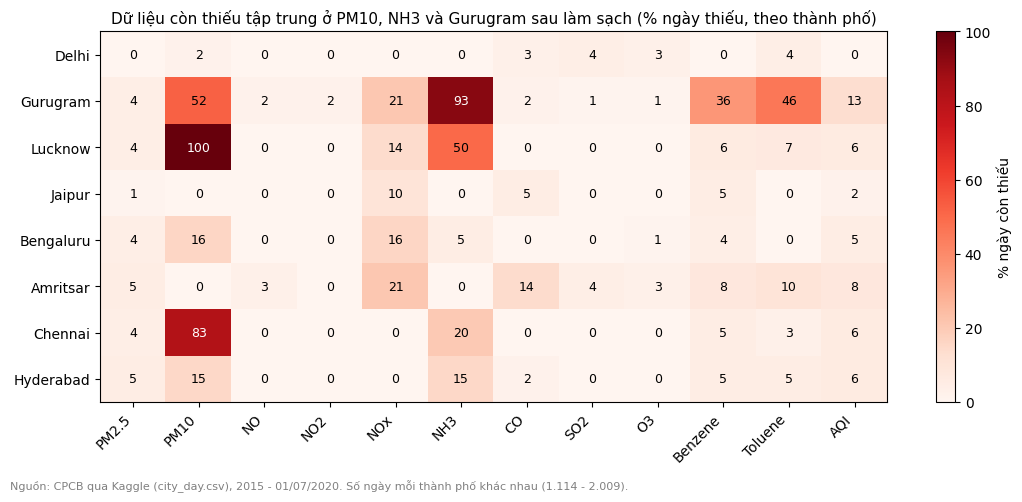

In [9]:
# Biểu đồ: % thiếu còn lại sau làm sạch
fig, ax = plt.subplots(figsize=(11, 5))
data = miss.values
im = ax.imshow(data, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(miss.columns, rotation=45, ha="right")
ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(miss.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                color="white" if v > 55 else "black", fontsize=9)
ax.set_title("Dữ liệu còn thiếu tập trung ở PM10, NH3 và Gurugram sau làm sạch (% ngày thiếu, theo thành phố)", fontsize=11)
fig.colorbar(im, ax=ax, label="% ngày còn thiếu")
fig.text(0.01, 0.01, "Nguồn: CPCB qua Kaggle (city_day.csv), 2015 - 01/07/2020. Số ngày mỗi thành phố khác nhau (1.114 - 2.009).",
         fontsize=8, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f"{REPORTS}/figures/missing_after_cleaning_8cities.png", dpi=150)
plt.show()